# Predicting Student Career Success After Graduation
### Capstone Project 24.1 — Final Report

**UC Berkeley Professional Certificate in Machine Learning and Artificial Intelligence**
**Author:** Jun Tie

---

## Business Understanding

University career-services offices have limited advising time. Today that time is spread evenly or goes to whoever asks for it, and the students most at risk of graduating without a job are often the ones who don't ask.

This project answers two questions:

1. **Can we predict, from measurable college-experience factors, whether a student will be placed in a job after graduation?** If so, career services can identify at-risk students early and reach out first.
2. **Which factors matter most?** Students and advisors need a data-driven ranking of which levers — internships, projects, skills, grades, English proficiency — make the biggest difference, so effort goes where it pays off.

**Success criteria:** a model that ranks students by placement likelihood clearly better than chance (and better than a "predict everyone is placed" baseline), plus an interpretable list of the factors that drive the prediction.

## Dataset

**Source:** [Student Career Success Prediction Dataset — Kaggle](https://www.kaggle.com/datasets/mobeenfatimah/student-career-success-prediction-dataset)
**File:** `data/student_career_success_dataset.csv` — 50,000 students × 29 columns (academics, skills, experience, digital presence, assessments, and placement outcomes).

## Table of Contents

1. [Setup](#1.-Setup)
2. [Data Loading & Inspection](#2.-Data-Loading-&-Inspection)
3. [Data Cleaning](#3.-Data-Cleaning)
4. [Feature Engineering](#4.-Feature-Engineering)
5. [Exploratory Data Analysis](#5.-Exploratory-Data-Analysis)
6. [Modeling Setup](#6.-Modeling-Setup)
7. [Model Training & Hyperparameter Tuning](#7.-Model-Training-&-Hyperparameter-Tuning)
8. [Model Comparison & Evaluation](#8.-Model-Comparison-&-Evaluation)
9. [Model Interpretation](#9.-Model-Interpretation)
10. [Findings, Recommendations & Next Steps](#10.-Findings,-Recommendations-&-Next-Steps)

## 1. Setup

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, accuracy_score,
    recall_score, precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 100

DATA_PATH = 'data/student_career_success_dataset.csv'
IMAGE_DIR = 'images'
RANDOM_STATE = 42
PLACED_COLOR, NOT_PLACED_COLOR = '#2196F3', '#F44336'


def save_fig(fig, name):
    # Save figures used in the README
    fig.savefig(f'{IMAGE_DIR}/{name}.png', bbox_inches='tight', dpi=120)

## 2. Data Loading & Inspection

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()

Shape: 50,000 rows x 29 columns


,Student_ID,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,...,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status,Company_Tier,Career_Field,Placement_Mode,Starting_Salary_USD
0,ST000001,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,...,7,8,Advanced,72,231.70,Placed,Tier 1,Backend Developer,Campus Placement,72082
1,ST000002,20,Female,Freshman,Computer Science,64,18,2.53,Poor,6,...,6,5,Basic,59,157.45,Not Placed,No Company,Not Placed,Not Applicable,0
2,ST000003,23,Male,Senior,Information Technology,75,19,2.83,Average,8,...,8,7,Advanced,76,203.45,Placed,Tier 1,IT Support Engineer,Campus Placement,94898
3,ST000004,23,Female,Senior,Information Technology,80,19,2.80,Average,5,...,6,6,Intermediate,67,171.50,Not Placed,No Company,Not Placed,Not Applicable,0
4,ST000005,23,Female,Senior,Software Engineering,73,19,2.93,Average,9,...,8,9,Advanced,82,225.45,Placed,Tier 1,Software Engineer,Internship Conversion,85256


In [3]:
# Column types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             50000 non-null  str    
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  str    
 3   University_Year        50000 non-null  str    
 4   Major                  50000 non-null  str    
 5   Attendance_Percentage  50000 non-null  int64  
 6   Study_Hours_Per_Week   50000 non-null  int64  
 7   CGPA                   50000 non-null  float64
 8   Academic_Performance   50000 non-null  str    
 9   Programming_Skill      50000 non-null  int64  
 10  Projects_Completed     50000 non-null  int64  
 11  Certifications         50000 non-null  int64  
 12  Hackathons             50000 non-null  int64  
 13  GitHub_Profile         50000 non-null  str    
 14  Internships            50000 non-null  int64  
 15  Leadership_Ex

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,50000.0,21.26,2.04,18.0,20.00,21.00,22.00,30.00
Attendance_Percentage,50000.0,81.41,9.71,50.0,75.00,82.00,88.00,100.00
Study_Hours_Per_Week,50000.0,21.53,6.97,5.0,17.00,21.00,26.00,45.00
CGPA,50000.0,3.11,0.29,2.0,2.91,3.11,3.31,4.00
Programming_Skill,50000.0,7.14,1.51,1.0,6.00,7.00,8.00,10.00
Projects_Completed,50000.0,8.62,2.51,0.0,7.00,9.00,10.00,15.00
Certifications,50000.0,1.72,1.37,0.0,1.00,2.00,3.00,8.00
Hackathons,50000.0,3.09,1.66,0.0,2.00,3.00,4.00,10.00
Internships,50000.0,4.05,1.01,0.0,3.00,4.00,5.00,5.00
Resume_Score,50000.0,96.05,7.33,44.0,95.00,100.00,100.00,100.00


## 3. Data Cleaning

In [5]:
# Missing values and duplicates
missing = df.isnull().sum()
print('Columns with missing values:', missing[missing > 0].to_dict() or 'none')
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate Student IDs:', df['Student_ID'].duplicated().sum())

Columns with missing values: none
Duplicate rows: 0
Duplicate Student IDs: 0


In [6]:
# Drop the identifier; create the binary target (1 = Placed)
df = df.drop(columns=['Student_ID'])
df['Placed'] = (df['Placement_Status'] == 'Placed').astype(int)

# Sanity checks: salary is 0 exactly for non-placed students; Academic_Performance is a CGPA band
print(df.groupby('Placement_Status')['Starting_Salary_USD'].agg(['min', 'max']))
print()
print(df.groupby('Academic_Performance')['CGPA'].agg(['min', 'max']).sort_values('min'))

                    min     max
Placement_Status               
Not Placed            0       0
Placed            25096  110000

                      min   max
Academic_Performance           
Poor                  2.0  2.59
Average               2.6  3.19
Good                  3.2  3.69
Excellent             3.7  4.00


In [7]:
# Outlier check (IQR rule) on the continuous features
continuous_cols = ['CGPA', 'Attendance_Percentage', 'Study_Hours_Per_Week',
                   'Resume_Score', 'Interview_Score', 'Age']


def iqr_outlier_share(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).mean()


outliers = pd.Series({col: iqr_outlier_share(df[col]) for col in continuous_cols}, name='Outlier share')
outliers.map('{:.2%}'.format)

CGPA                      0.53%
Attendance_Percentage     0.50%
Study_Hours_Per_Week      0.49%
Resume_Score             12.71%
Interview_Score           0.98%
Age                       4.07%
Name: Outlier share, dtype: str

**Cleaning summary**
- No missing values and no duplicate rows or student IDs.
- `Starting_Salary_USD = 0` for every non-placed student — structurally correct, not missing data.
- `Academic_Performance` is a banded version of `CGPA` (Poor < 2.6 ≤ Average < 3.2 ≤ Good < 3.7 ≤ Excellent). It is useful for charts but redundant for modeling, so only `CGPA` goes into the models.
- Outliers affect well under 1% of rows and all values are plausible (e.g., a low interview score), so no rows are removed.

## 4. Feature Engineering

In [8]:
# Binary flags for Yes/No columns
for col in ['GitHub_Profile', 'LinkedIn_Profile', 'Leadership_Experience']:
    df[col] = (df[col] == 'Yes').astype(int)

# Ordinal encodings
df['English_Level'] = df['English_Proficiency'].map({'Basic': 0, 'Intermediate': 1, 'Advanced': 2})

# Internship density: internships per semester completed so far
semesters = df['University_Year'].map({'Freshman': 2, 'Sophomore': 4, 'Junior': 6, 'Senior': 8})
df['Internship_Density'] = df['Internships'] / semesters

# Composite scores used for EDA
df['Tech_Readiness'] = (df['Programming_Skill'] + df['Projects_Completed']
                        + 2 * df['Certifications'] + df['Hackathons'])
df['Soft_Skills'] = df[['Communication_Skills', 'Teamwork', 'Problem_Solving']].mean(axis=1)

df[['English_Level', 'Internship_Density', 'Tech_Readiness', 'Soft_Skills']].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
English_Level,50000.0,1.78,0.44,0.0,2.00,2.00,2.00,2.0
Internship_Density,50000.0,0.98,0.62,0.0,0.50,0.83,1.25,2.5
Tech_Readiness,50000.0,22.28,5.40,3.0,19.00,22.00,26.00,42.0
Soft_Skills,50000.0,7.54,1.13,3.0,6.67,7.67,8.33,10.0


`Tech_Readiness` and `Soft_Skills` are exact linear combinations of features that are already in the model. Adding them gives the models no new information and makes the logistic regression coefficients harder to read, so they are used only in EDA. `Internship_Density` is kept for modeling because it adds the student's year of study to the internship count, which is not a linear combination of existing features.

## 5. Exploratory Data Analysis

### 5.1 Target Variable

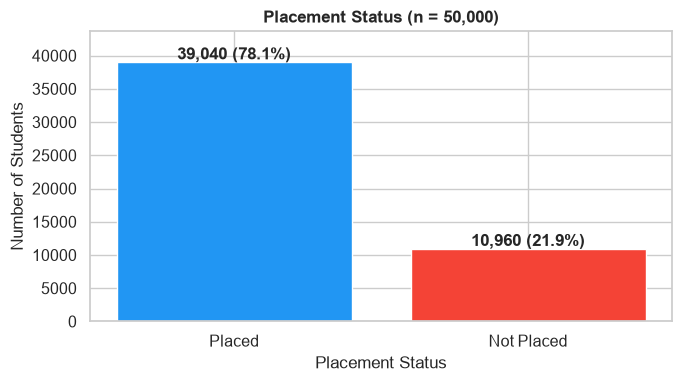

In [9]:
counts = df['Placement_Status'].value_counts()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(counts.index, counts.values, color=[PLACED_COLOR, NOT_PLACED_COLOR])
for i, v in enumerate(counts.values):
    ax.text(i, v + 400, f'{v:,} ({v / len(df):.1%})', ha='center', fontweight='bold')
ax.set_title('Placement Status (n = 50,000)', fontweight='bold')
ax.set_xlabel('Placement Status')
ax.set_ylabel('Number of Students')
ax.set_ylim(0, counts.max() * 1.12)
plt.tight_layout()
plt.show()

78% of students are placed and 22% are not. This moderate imbalance means a model that predicts "Placed" for everyone would be 78% accurate while being useless for finding at-risk students. Accuracy is therefore **not** the primary metric (see Section 6).

### 5.2 Experience Factors

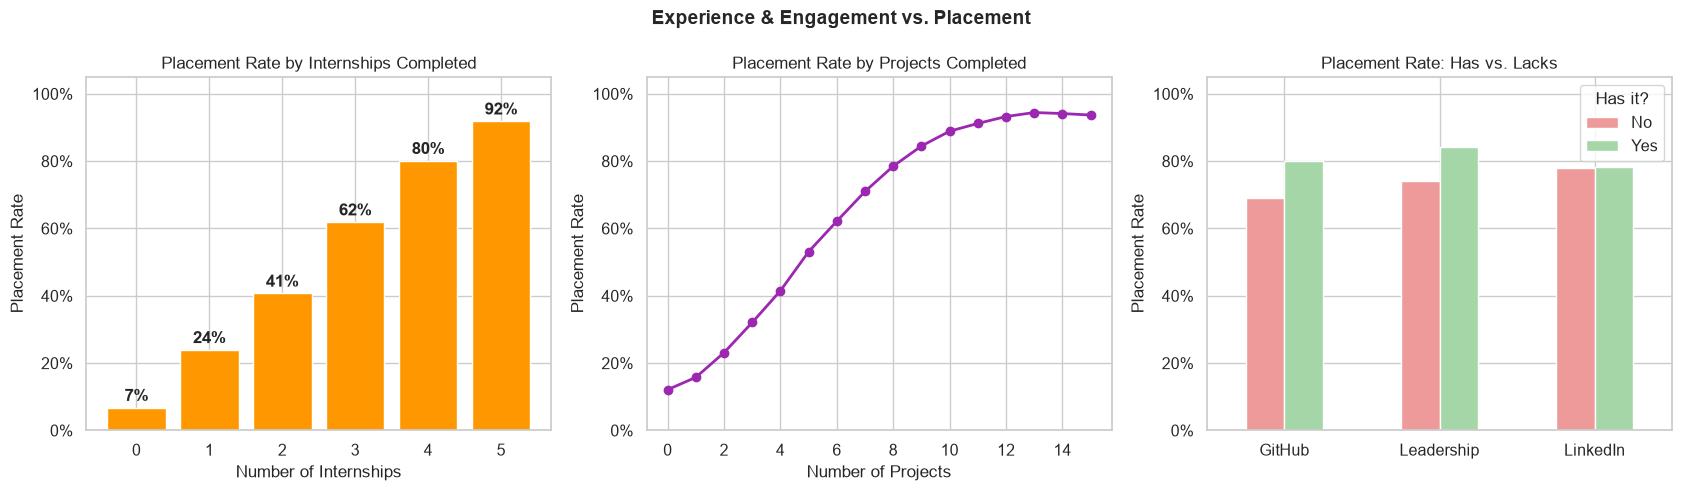

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Placement rate by number of internships
intern_rate = df.groupby('Internships')['Placed'].mean()
axes[0].bar(intern_rate.index, intern_rate.values, color='#FF9800')
for x, v in zip(intern_rate.index, intern_rate.values):
    axes[0].text(x, v + 0.02, f'{v:.0%}', ha='center', fontweight='bold')
axes[0].set_title('Placement Rate by Internships Completed')
axes[0].set_xlabel('Number of Internships')

# Placement rate by projects completed
proj_rate = df.groupby('Projects_Completed')['Placed'].mean()
axes[1].plot(proj_rate.index, proj_rate.values, marker='o', color='#9C27B0', linewidth=2)
axes[1].set_title('Placement Rate by Projects Completed')
axes[1].set_xlabel('Number of Projects')

# Lift from GitHub profile / leadership / LinkedIn
flag_cols = {'GitHub_Profile': 'GitHub', 'Leadership_Experience': 'Leadership', 'LinkedIn_Profile': 'LinkedIn'}
flag_rates = pd.DataFrame({label: df.groupby(col)['Placed'].mean() for col, label in flag_cols.items()}).T
flag_rates.columns = ['No', 'Yes']
flag_rates.plot.bar(ax=axes[2], color=['#EF9A9A', '#A5D6A7'], rot=0)
axes[2].set_title('Placement Rate: Has vs. Lacks')
axes[2].set_xlabel('')
axes[2].legend(title='Has it?')

for ax in axes:
    ax.set_ylabel('Placement Rate')
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

fig.suptitle('Experience & Engagement vs. Placement', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

- **Internships have the steepest effect of any single factor:** 7% of students with no internships are placed versus 92% of those with five.
- Placement rises steadily with each completed project.
- In the raw data, a GitHub profile and leadership experience each go with about 10 percentage points higher placement. A LinkedIn profile makes almost no difference.

### 5.3 Academic & Skill Factors

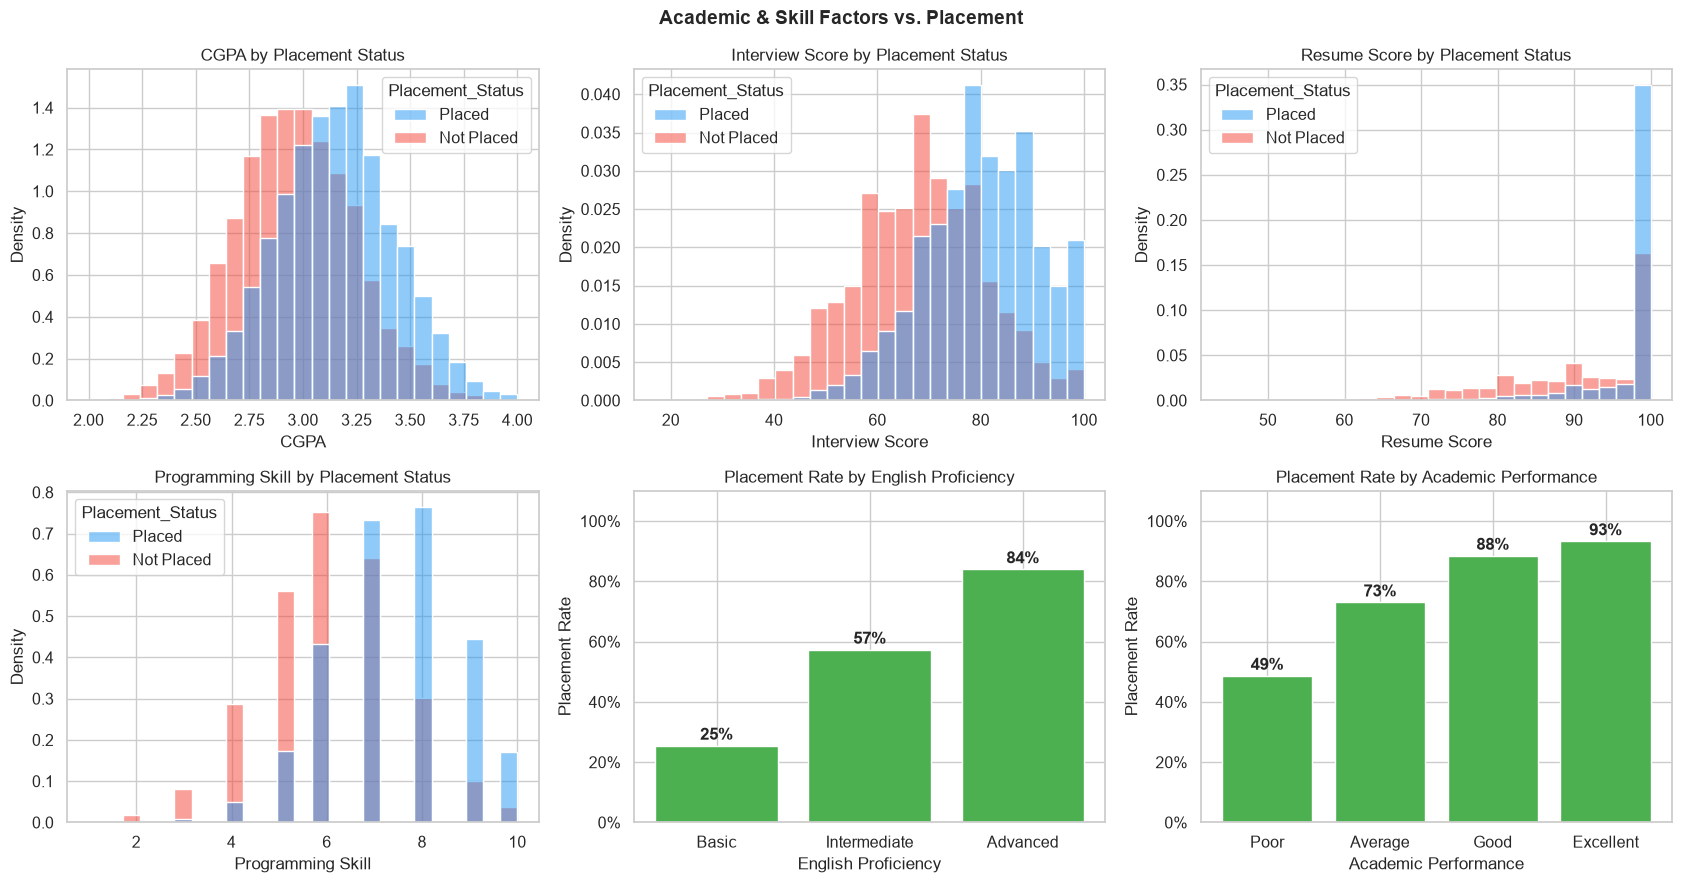

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()

# Continuous features: overlaid density histograms by placement status
for ax, col in zip(axes[:4], ['CGPA', 'Interview_Score', 'Resume_Score', 'Programming_Skill']):
    sns.histplot(data=df, x=col, hue='Placement_Status', stat='density', common_norm=False,
                 bins=25, alpha=0.5, ax=ax,
                 palette={'Placed': PLACED_COLOR, 'Not Placed': NOT_PLACED_COLOR})
    ax.set_title(f'{col.replace("_", " ")} by Placement Status')
    ax.set_xlabel(col.replace('_', ' '))

# Categorical features: placement rate by English proficiency and academic band
for ax, col, order in [
    (axes[4], 'English_Proficiency', ['Basic', 'Intermediate', 'Advanced']),
    (axes[5], 'Academic_Performance', ['Poor', 'Average', 'Good', 'Excellent']),
]:
    rate = df.groupby(col)['Placed'].mean().reindex(order)
    ax.bar(rate.index, rate.values, color='#4CAF50')
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.02, f'{v:.0%}', ha='center', fontweight='bold')
    ax.set_title(f'Placement Rate by {col.replace("_", " ")}')
    ax.set_xlabel(col.replace('_', ' '))
    ax.set_ylabel('Placement Rate')
    ax.set_ylim(0, 1.1)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

fig.suptitle('Academic & Skill Factors vs. Placement', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

- Placed students score noticeably higher on interviews, resumes, and programming skill.
- **English proficiency shows a large raw gap:** 26% of students with Basic English are placed versus 84% with Advanced. Section 9.4 shows that this gap mostly works through interview performance.
- CGPA matters: placement rises steadily across the GPA bands from Poor to Excellent.

### 5.4 Major, Year, and Gender

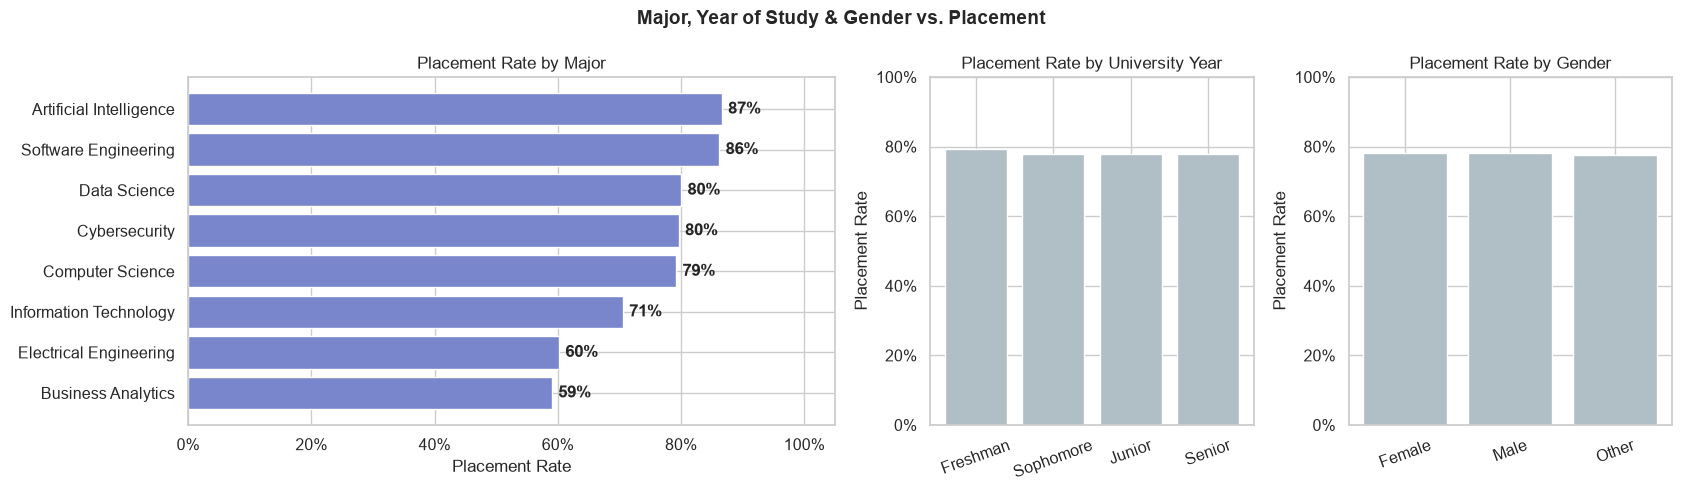

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={'width_ratios': [2, 1, 1]})

major_rate = df.groupby('Major')['Placed'].mean().sort_values()
axes[0].barh(major_rate.index, major_rate.values, color='#7986CB')
for i, v in enumerate(major_rate.values):
    axes[0].text(v + 0.01, i, f'{v:.0%}', va='center', fontweight='bold')
axes[0].set_title('Placement Rate by Major')
axes[0].set_xlabel('Placement Rate')
axes[0].set_xlim(0, 1.05)
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

for ax, col, order in [
    (axes[1], 'University_Year', ['Freshman', 'Sophomore', 'Junior', 'Senior']),
    (axes[2], 'Gender', None),
]:
    rate = df.groupby(col)['Placed'].mean()
    rate = rate.reindex(order) if order else rate
    ax.bar(rate.index, rate.values, color='#B0BEC5')
    ax.set_title(f'Placement Rate by {col.replace("_", " ")}')
    ax.set_ylabel('Placement Rate')
    ax.set_ylim(0, 1.0)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.tick_params(axis='x', rotation=20)

fig.suptitle('Major, Year of Study & Gender vs. Placement', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

- AI and Software Engineering majors are placed at about 86%. Business Analytics and Electrical Engineering are placed at about 60%.
- Year of study and gender barely affect placement (Female 78.1%, Male 78.1%, Other 77.5%), which is reassuring from a fairness standpoint.

### 5.5 Correlations

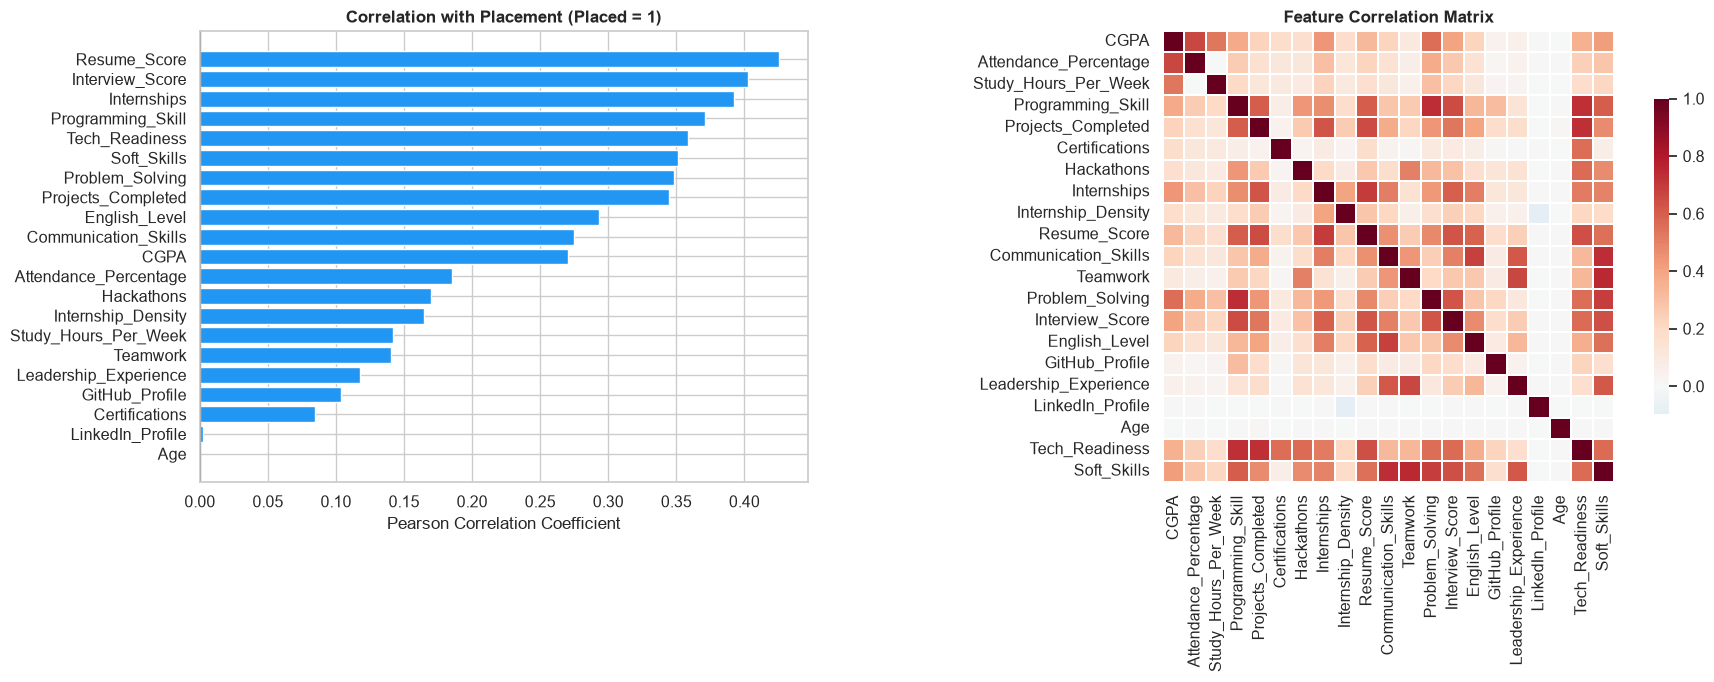

In [13]:
corr_features = ['CGPA', 'Attendance_Percentage', 'Study_Hours_Per_Week', 'Programming_Skill',
                 'Projects_Completed', 'Certifications', 'Hackathons', 'Internships',
                 'Internship_Density', 'Resume_Score', 'Communication_Skills', 'Teamwork',
                 'Problem_Solving', 'Interview_Score', 'English_Level', 'GitHub_Profile',
                 'Leadership_Experience', 'LinkedIn_Profile', 'Age', 'Tech_Readiness', 'Soft_Skills']

target_corr = df[corr_features + ['Placed']].corr()['Placed'].drop('Placed').sort_values()

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1, 1.3]})
axes[0].barh(target_corr.index, target_corr.values,
             color=[PLACED_COLOR if v > 0 else NOT_PLACED_COLOR for v in target_corr.values])
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Correlation with Placement (Placed = 1)', fontweight='bold')
axes[0].set_xlabel('Pearson Correlation Coefficient')

sns.heatmap(df[corr_features].corr(), cmap='RdBu_r', center=0, square=True,
            linewidths=0.3, cbar_kws={'shrink': 0.7}, ax=axes[1])
axes[1].set_title('Feature Correlation Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

- Resume score, interview score, and internships correlate most strongly with placement (r ≈ 0.4 each).
- Apart from the composite scores and the scores they are built from, the features are only weakly correlated with each other. This means no single feature is a duplicate of another and each can contribute on its own.

### 5.6 Are the Placement Gaps Statistically Significant?
The charts above describe *this* sample of 50,000 students. Inferential tests ask whether each gap is likely to hold for students in general, or whether it could be random noise.

- **Categorical factors** (e.g., internships, English level, major, gender): **chi-square test of independence**. The null hypothesis is that placement rate is the same in every group.
- **Continuous factors** (e.g., CGPA, interview score): **Welch's t-test** comparing placed and not-placed students. The null hypothesis is that both groups have the same mean.
- Because 15 tests are run at once, the significance threshold is **Bonferroni-corrected** to 0.05 / 15 ≈ 0.0033.

With 50,000 students, even tiny differences can come out "significant." So each test also reports an **effect size**, which shows whether a difference is big enough to matter:
- **Cramér's V** (categorical): 0.1 = small, 0.3 = medium, 0.5 = large.
- **Cohen's d** (continuous): 0.2 = small, 0.5 = medium, 0.8 = large.

In [14]:
CATEGORICAL_TESTS = ['Internships', 'English_Proficiency', 'Major', 'GitHub_Profile',
                     'Leadership_Experience', 'LinkedIn_Profile', 'University_Year', 'Gender']
CONTINUOUS_TESTS = ['Interview_Score', 'Resume_Score', 'Programming_Skill', 'Projects_Completed',
                    'CGPA', 'Study_Hours_Per_Week', 'Age']
ALPHA = 0.05 / (len(CATEGORICAL_TESTS) + len(CONTINUOUS_TESTS))


def magnitude(value, cutoffs):
    # Conventional small / medium / large labels for an effect size
    small, medium, large = cutoffs
    value = abs(value)
    return 'Large' if value >= large else 'Medium' if value >= medium else 'Small' if value >= small else 'Negligible'


rows = []
for col in CATEGORICAL_TESTS:
    table = pd.crosstab(df[col], df['Placed'])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({'Factor': col, 'Test': f'Chi-square (df={dof})', 'Statistic': chi2, 'p-value': p,
                 'Effect size': cramers_v, 'Measure': "Cramér's V",
                 'Magnitude': magnitude(cramers_v, (0.1, 0.3, 0.5))})

for col in CONTINUOUS_TESTS:
    placed, not_placed = df.loc[df['Placed'] == 1, col], df.loc[df['Placed'] == 0, col]
    t_stat, p = stats.ttest_ind(placed, not_placed, equal_var=False)
    cohens_d = (placed.mean() - not_placed.mean()) / np.sqrt((placed.var() + not_placed.var()) / 2)
    rows.append({'Factor': col, 'Test': "Welch's t-test", 'Statistic': t_stat, 'p-value': p,
                 'Effect size': cohens_d, 'Measure': "Cohen's d",
                 'Magnitude': magnitude(cohens_d, (0.2, 0.5, 0.8))})

sig_tests = pd.DataFrame(rows).set_index('Factor')
sig_tests['Significant?'] = np.where(sig_tests['p-value'] < ALPHA, 'Yes', 'No')
sig_tests = sig_tests.sort_values(['Measure', 'Effect size'], ascending=[True, False])

(sig_tests.style
    .format({'Statistic': '{:,.1f}', 'Effect size': '{:.3f}',
             'p-value': lambda p: '&lt; 0.001' if p < 0.001 else f'{p:.3f}'})
    .set_caption(f'Significance tests for placement gaps (Bonferroni-corrected alpha = {ALPHA:.4f})'))

,Test,Statistic,p-value,Effect size,Measure,Magnitude,Significant?
Factor,,,,,,,
Interview_Score,Welch's t-test,90.3,< 0.001,1.017,Cohen's d,Large,Yes
Programming_Skill,Welch's t-test,85.7,< 0.001,0.945,Cohen's d,Large,Yes
Resume_Score,Welch's t-test,74.3,< 0.001,0.927,Cohen's d,Large,Yes
Projects_Completed,Welch's t-test,79.9,< 0.001,0.875,Cohen's d,Large,Yes
CGPA,Welch's t-test,62.7,< 0.001,0.678,Cohen's d,Medium,Yes
Study_Hours_Per_Week,Welch's t-test,32.4,< 0.001,0.348,Cohen's d,Small,Yes
Age,Welch's t-test,0.1,0.927,0.001,Cohen's d,Negligible,No
Internships,Chi-square (df=5),"7,835.6",< 0.001,0.396,Cramér's V,Medium,Yes
English_Proficiency,Chi-square (df=2),"4,301.4",< 0.001,0.293,Cramér's V,Small,Yes


**Interpretation**
- **Large, significant differences** (Cohen's d ≥ 0.8): placed students score substantially higher on **interviews (d = 1.02), programming skill (0.95), resume (0.93), and projects completed (0.88)**. CGPA has a medium effect (0.68), and study hours a small one (0.35).
- **Internships** have the strongest link among the categorical factors (Cramér's V = 0.40, medium). English proficiency (0.29), major (0.21), leadership (0.12), and GitHub (0.10) are significant but small.
- **Not significant:** **gender (p = 0.90)**, LinkedIn profile (p = 0.62), age (p = 0.93), and year of study (p = 0.035, above the corrected threshold). We find no evidence that these relate to placement, which statistically confirms the "no gender effect" result.
- These tests examine each factor **on its own**. Section 9.4 shows that some significant gaps (English, major, GitHub, leadership) mostly disappear once the other factors are held fixed.

## 6. Modeling Setup

### Features
Only information that is known **before** placement is used. The following columns are excluded:

| Excluded column | Reason |
|---|---|
| `Company_Tier`, `Career_Field`, `Placement_Mode`, `Starting_Salary_USD` | Recorded *after* placement — direct target leakage |
| `Employability_Score` | A composite assessment score of undocumented construction that may encode the outcome; excluded to keep the model honest and interpretable |
| `Academic_Performance` | Redundant band of `CGPA` |
| `Tech_Readiness`, `Soft_Skills` | Linear combinations of included features |

Numeric features are standardized. `Major`, `University_Year`, and `Gender` are one-hot encoded. Gender is included only so we can confirm it carries no predictive weight.

### Evaluation Metric
**Primary metric: ROC-AUC.** The business use is *ranking* students by risk so advisors can work down the list. ROC-AUC measures exactly that: the probability that the model scores a randomly chosen placed student above a randomly chosen non-placed one. It is unaffected by the 78/22 imbalance and doesn't depend on choosing a cutoff (0.5 = chance, 1.0 = perfect).

**Supporting metrics:**
- **Recall on Not Placed** — the share of truly at-risk students the model catches.
- **F1 (Not Placed)** — balances catching at-risk students with not flagging too many who would have been fine.
- **Average precision (PR-AUC)** for the Not Placed class.
- **Accuracy** is reported only for context.

### Validation
- 80/20 stratified train/test split. The test set is held out until final evaluation.
- Every model is tuned with `GridSearchCV` using **5-fold stratified cross-validation** on the training set, scored by ROC-AUC.

In [15]:
NUMERIC_FEATURES = [
    'CGPA', 'Attendance_Percentage', 'Study_Hours_Per_Week', 'Programming_Skill',
    'Projects_Completed', 'Certifications', 'Hackathons', 'Internships', 'Internship_Density',
    'Resume_Score', 'Communication_Skills', 'Teamwork', 'Problem_Solving', 'Interview_Score',
    'English_Level', 'GitHub_Profile', 'LinkedIn_Profile', 'Leadership_Experience', 'Age',
]
CATEGORICAL_FEATURES = ['Major', 'University_Year', 'Gender']

X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = df['Placed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), NUMERIC_FEATURES),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f'Train: {len(X_train):,} rows ({y_train.mean():.1%} placed)')
print(f'Test:  {len(X_test):,} rows ({y_test.mean():.1%} placed)')

Train: 40,000 rows (78.1% placed)
Test:  10,000 rows (78.1% placed)


## 7. Model Training & Hyperparameter Tuning

Six candidates, from simplest to most flexible:

| Model | Why it is included |
|---|---|
| Dummy (most frequent) | Floor: what you get without a model |
| Logistic Regression | Interpretable linear baseline from Module 20, now tuned |
| K-Nearest Neighbors | Non-parametric, "students like you" approach |
| Decision Tree | Human-readable rules, captures thresholds |
| Random Forest | Ensemble of trees, captures non-linear interactions |
| Gradient Boosting (HistGradientBoosting) | Typically the strongest on tabular data |

Class weights are balanced (where supported) so the minority Not Placed class gets equal attention during training.

In [16]:
model_grids = {
    'Logistic Regression': (
        LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
        {'model__C': [0.001, 0.01, 0.1, 1, 10]},
    ),
    'K-Nearest Neighbors': (
        KNeighborsClassifier(),
        {'model__n_neighbors': [25, 75, 151], 'model__weights': ['uniform', 'distance']},
    ),
    'Decision Tree': (
        DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        {'model__max_depth': [4, 6, 8, 12], 'model__min_samples_leaf': [20, 100, 300]},
    ),
    'Random Forest': (
        RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE),
        {'model__max_depth': [8, 16, None], 'model__min_samples_leaf': [5, 20, 50],
         'model__max_features': ['sqrt', 0.5]},
    ),
    'Gradient Boosting': (
        HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        {'model__learning_rate': [0.03, 0.1], 'model__max_depth': [3, 6],
         'model__max_iter': [200, 400], 'model__l2_regularization': [0.0, 1.0]},
    ),
}

searches = {}
for name, (estimator, grid) in model_grids.items():
    start = time.time()
    pipe = Pipeline([('prep', preprocessor), ('model', estimator)])
    search = GridSearchCV(pipe, grid, scoring='roc_auc', cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
    best = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
    print(f'{name:<20} CV ROC-AUC = {search.best_score_:.4f}  ({time.time() - start:5.1f}s)  best: {best}')

# Dummy baseline needs no tuning
dummy = Pipeline([('prep', preprocessor), ('model', DummyClassifier(strategy='most_frequent'))]).fit(X_train, y_train)

Logistic Regression  CV ROC-AUC = 0.8115  (  2.0s)  best: {'C': 0.001}


K-Nearest Neighbors  CV ROC-AUC = 0.8059  (  2.1s)  best: {'n_neighbors': 151, 'weights': 'uniform'}


Decision Tree        CV ROC-AUC = 0.7984  (  0.8s)  best: {'max_depth': 8, 'min_samples_leaf': 300}


Random Forest        CV ROC-AUC = 0.8093  ( 58.1s)  best: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 20}


Gradient Boosting    CV ROC-AUC = 0.8081  (  5.2s)  best: {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 400}


In [17]:
# How sensitive is each model to its hyperparameters? Spread of CV ROC-AUC across each grid
grid_spread = pd.DataFrame({
    name: pd.Series(s.cv_results_['mean_test_score']).describe()[['min', 'max']]
    for name, s in searches.items()
}).T
grid_spread['range'] = grid_spread['max'] - grid_spread['min']
grid_spread.round(4)

,min,max,range
Logistic Regression,0.8114,0.8115,0.0001
K-Nearest Neighbors,0.7884,0.8059,0.0174
Decision Tree,0.7630,0.7984,0.0354
Random Forest,0.8041,0.8093,0.0052
Gradient Boosting,0.8063,0.8081,0.0018


## 8. Model Comparison & Evaluation

In [18]:
# Evaluate every tuned model on the held-out test set.
# Metrics for the at-risk (Not Placed) class use 1 - P(placed) as the risk score.
fitted_models = {'Dummy (most frequent)': dummy, **{n: s.best_estimator_ for n, s in searches.items()}}

rows = []
for name, model in fitted_models.items():
    prob_placed = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    rows.append({
        'Model': name,
        'CV ROC-AUC': searches[name].best_score_ if name in searches else np.nan,
        'Test ROC-AUC': roc_auc_score(y_test, prob_placed),
        'Recall (Not Placed)': recall_score(y_test, pred, pos_label=0),
        'Precision (Not Placed)': precision_score(y_test, pred, pos_label=0, zero_division=0),
        'F1 (Not Placed)': f1_score(y_test, pred, pos_label=0),
        'PR-AUC (Not Placed)': average_precision_score(1 - y_test, 1 - prob_placed),
        'Accuracy': accuracy_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index('Model').sort_values('Test ROC-AUC', ascending=False)

# Display as a single formatted table; bold the best value in each column (excluding the dummy)
real_models = results.index.drop('Dummy (most frequent)')
(results.style
    .format('{:.3f}', na_rep='—')
    .highlight_max(subset=(real_models, results.columns), props='font-weight: bold; background-color: #E8EAF6')
    .set_caption('Test-set performance of tuned models (best value per column highlighted)'))

,CV ROC-AUC,Test ROC-AUC,Recall (Not Placed),Precision (Not Placed),F1 (Not Placed),PR-AUC (Not Placed),Accuracy
Model,,,,,,,
Logistic Regression,0.812,0.803,0.707,0.444,0.546,0.567,0.742
Random Forest,0.809,0.800,0.706,0.443,0.544,0.560,0.741
Gradient Boosting,0.808,0.799,0.720,0.433,0.541,0.563,0.732
K-Nearest Neighbors,0.806,0.798,0.306,0.664,0.419,0.552,0.814
Decision Tree,0.798,0.791,0.715,0.426,0.534,0.537,0.726
Dummy (most frequent),—,0.500,0.000,0.000,0.000,0.219,0.781


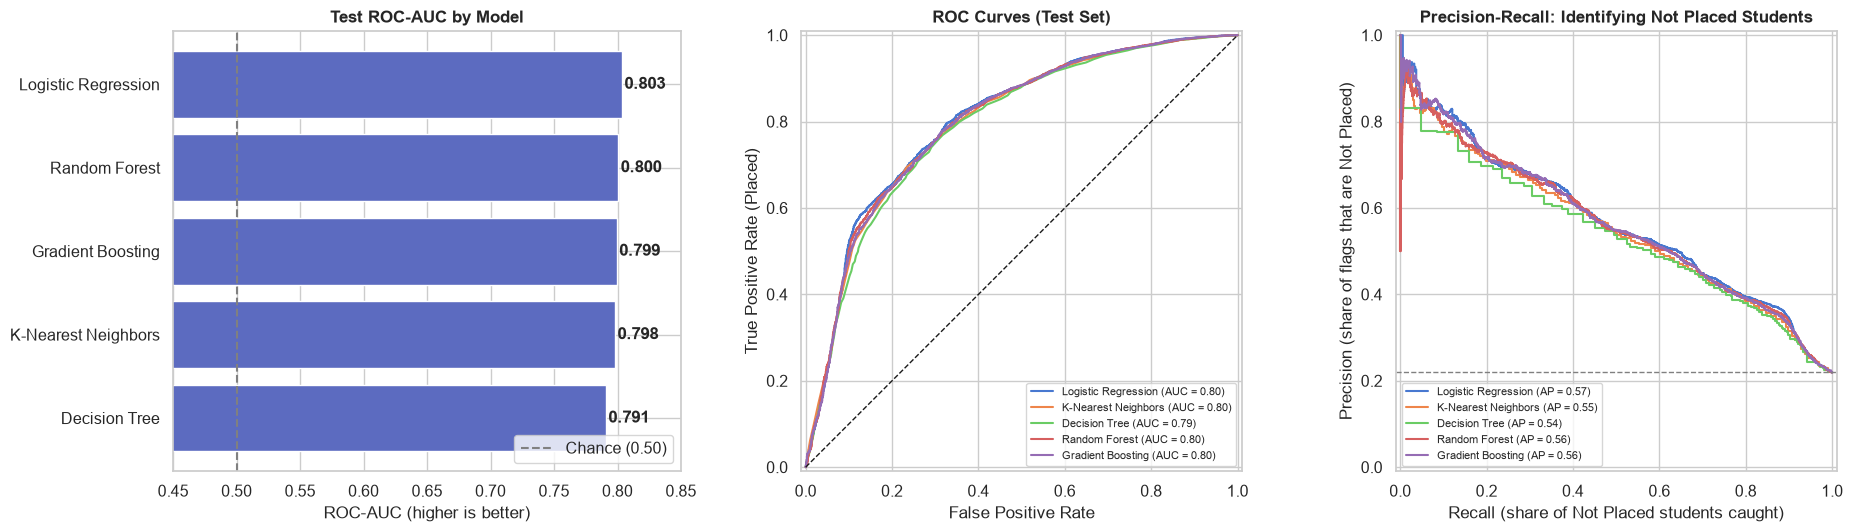

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# Test ROC-AUC by model
plot_df = results.drop(index='Dummy (most frequent)').sort_values('Test ROC-AUC')
axes[0].barh(plot_df.index, plot_df['Test ROC-AUC'], color='#5C6BC0')
for i, v in enumerate(plot_df['Test ROC-AUC']):
    axes[0].text(v + 0.002, i, f'{v:.3f}', va='center', fontweight='bold')
axes[0].axvline(0.5, color='grey', linestyle='--', label='Chance (0.50)')
axes[0].set_xlim(0.45, 0.85)
axes[0].set_title('Test ROC-AUC by Model', fontweight='bold')
axes[0].set_xlabel('ROC-AUC (higher is better)')
axes[0].legend(loc='lower right')

# ROC and precision-recall (Not Placed) curves
for name, model in fitted_models.items():
    if name.startswith('Dummy'):
        continue
    prob_placed = model.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, prob_placed, name=name, ax=axes[1])
    PrecisionRecallDisplay.from_predictions(1 - y_test, 1 - prob_placed, name=name, ax=axes[2])
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[1].set_title('ROC Curves (Test Set)', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Placed)')
axes[2].axhline((1 - y_test).mean(), color='grey', linestyle='--', linewidth=1)
axes[2].set_title('Precision-Recall: Identifying Not Placed Students', fontweight='bold')
axes[2].set_xlabel('Recall (share of Not Placed students caught)')
axes[2].set_ylabel('Precision (share of flags that are Not Placed)')
for ax in axes[1:]:
    ax.legend(fontsize=8, loc='lower left' if ax is axes[2] else 'lower right')

plt.tight_layout()
save_fig(fig, 'model_comparison')
plt.show()

In [20]:
best_name = results.drop(index='Dummy (most frequent)')['Test ROC-AUC'].idxmax()
best_model = fitted_models[best_name]
print(f'Best model on test ROC-AUC: {best_name}')
print()
print(classification_report(y_test, best_model.predict(X_test), target_names=['Not Placed', 'Placed']))

Best model on test ROC-AUC: Logistic Regression

              precision    recall  f1-score   support

  Not Placed       0.44      0.71      0.55      2192
      Placed       0.90      0.75      0.82      7808

    accuracy                           0.74     10000
   macro avg       0.67      0.73      0.68     10000
weighted avg       0.80      0.74      0.76     10000



**Interpreting the comparison**

- All tuned models beat the dummy baseline by a wide margin. The dummy is 78% accurate but catches **zero** at-risk students, and its ROC-AUC of 0.50 is no better than chance.
- **Logistic Regression, Random Forest, and Gradient Boosting all reach a test ROC-AUC of about 0.80.** The differences are in the third decimal place. Section 8.1 tests whether they are statistically real. KNN and the single Decision Tree are slightly behind.
- KNN has the highest accuracy, but only because it rarely predicts "Not Placed": it catches about 31% of at-risk students, compared with about 71% for the class-weighted models. This is exactly why accuracy is not the primary metric.
- The fact that flexible tree ensembles do not beat a linear model tells us something about the data: **each factor's effect on placement is mostly steady and additive.** Each extra internship, project, or interview point raises the odds by a roughly consistent amount, and there are no strong hidden interactions for the trees to find.
- Hyperparameters barely matter (see the grid-spread table). The ceiling of about 0.80 comes from the information in the features, not from model tuning. Students who look alike on paper sometimes have different outcomes, and those outcomes depend on things not captured in the data.
- **Selected model: Logistic Regression.** It ties for the best performance and is the easiest to explain to students and advisors. Its coefficients translate directly into "how much does this factor change your odds?"

### 8.1 Are the Differences Between Models Real? (Bootstrap Confidence Intervals)
The test set is one sample of 10,000 students, so each test ROC-AUC is an estimate with some uncertainty. To measure that uncertainty, we **bootstrap**: resample the test set with replacement 1,000 times and recompute every model's ROC-AUC on each resample. This gives:
- a **95% confidence interval** for each model's ROC-AUC, and
- a **paired test** of whether each model differs from the selected model. Both are scored on the same resamples, so the comparison is fair.

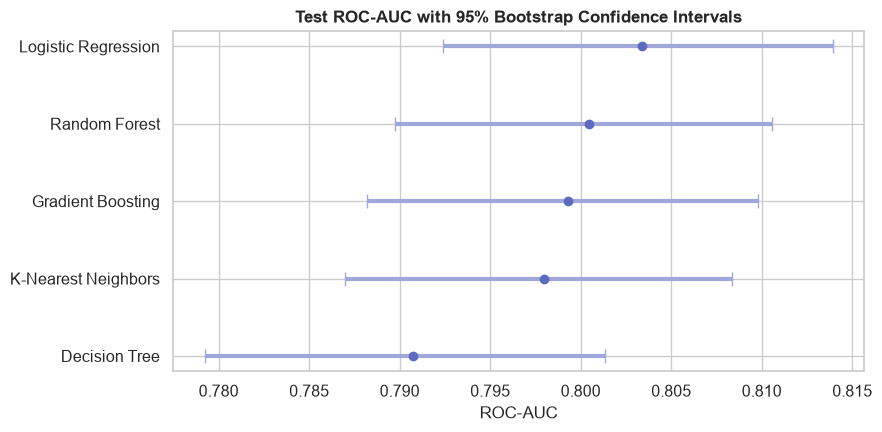

,Test ROC-AUC,95% CI low,95% CI high,Diff vs. Logistic Regression,Diff 95% CI low,Diff 95% CI high,p-value
Logistic Regression,0.8034,0.7924,0.8139,—,—,—,—
Random Forest,0.8005,0.7897,0.8106,-0.0029,-0.0047,-0.0010,0.006
Gradient Boosting,0.7993,0.7882,0.8098,-0.0040,-0.0059,-0.0022,< 0.001
K-Nearest Neighbors,0.7980,0.7870,0.8084,-0.0054,-0.0082,-0.0026,< 0.001
Decision Tree,0.7907,0.7792,0.8013,-0.0127,-0.0168,-0.0085,< 0.001


In [21]:
rng = np.random.default_rng(RANDOM_STATE)
N_BOOT = 1000
y_arr = y_test.to_numpy()
test_probs = {name: model.predict_proba(X_test)[:, 1]
              for name, model in fitted_models.items() if not name.startswith('Dummy')}

boot_auc = {name: np.empty(N_BOOT) for name in test_probs}
for b in range(N_BOOT):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    for name, prob in test_probs.items():
        boot_auc[name][b] = roc_auc_score(y_arr[idx], prob[idx])
boot_auc = pd.DataFrame(boot_auc)

# Paired differences vs. the selected model; two-sided bootstrap p-value
diff = boot_auc.sub(boot_auc[best_name], axis=0)
ci_table = pd.DataFrame({
    'Test ROC-AUC': results.loc[test_probs.keys(), 'Test ROC-AUC'],
    '95% CI low': boot_auc.quantile(0.025),
    '95% CI high': boot_auc.quantile(0.975),
    f'Diff vs. {best_name}': diff.mean(),
    'Diff 95% CI low': diff.quantile(0.025),
    'Diff 95% CI high': diff.quantile(0.975),
    'p-value': 2 * np.minimum((diff <= 0).mean(), (diff >= 0).mean()).clip(upper=0.5),
}).sort_values('Test ROC-AUC', ascending=False)
ci_table.loc[best_name, [f'Diff vs. {best_name}', 'Diff 95% CI low', 'Diff 95% CI high', 'p-value']] = np.nan

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_ci = ci_table.sort_values('Test ROC-AUC')
ax.errorbar(plot_ci['Test ROC-AUC'], plot_ci.index,
            xerr=[plot_ci['Test ROC-AUC'] - plot_ci['95% CI low'], plot_ci['95% CI high'] - plot_ci['Test ROC-AUC']],
            fmt='o', color='#5C6BC0', ecolor='#9FA8DA', elinewidth=3, capsize=5)
ax.set_title('Test ROC-AUC with 95% Bootstrap Confidence Intervals', fontweight='bold')
ax.set_xlabel('ROC-AUC')
plt.tight_layout()
plt.show()

ci_formats = {col: '{:.4f}' for col in ci_table.columns}
ci_formats['p-value'] = lambda p: '&lt; 0.001' if p < 0.001 else f'{p:.3f}'
ci_table.style.format(ci_formats, na_rep='—')

**Interpretation**
- Each model's ROC-AUC is precise to about **±0.011** (95% CI), and the intervals of all five models overlap.
- The paired comparison is more sensitive, because every model is scored on the same resampled students. It shows that Logistic Regression is **statistically** better than every other model (all p < 0.01). But the margins are tiny: 0.003 AUC over Random Forest and 0.004 over Gradient Boosting.
- This is a clear case of *statistically significant but practically negligible*. No advisor would notice a 0.003 difference in ranking quality. What it does rule out is that the complex models are hiding extra predictive power: **the simplest model is at least as good as the most complex ones.**

### 8.2 Practical Use: Prioritizing Outreach

ROC-AUC is abstract, so here is what the model means for a career-services office. Rank test-set students by predicted risk and imagine advisors can reach only the top *k*% of the list.

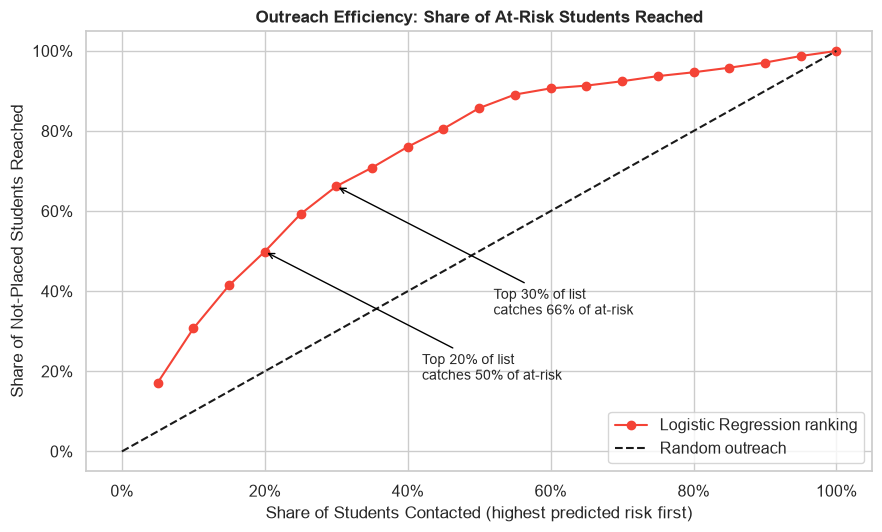

,Share contacted,At-risk students reached,Lift vs. random
1,10%,31%,3.1x
3,20%,50%,2.5x
5,30%,66%,2.2x
9,50%,86%,1.7x


In [22]:
risk = 1 - best_model.predict_proba(X_test)[:, 1]
outreach = pd.DataFrame({'risk': risk, 'not_placed': (1 - y_test).values}).sort_values('risk', ascending=False)
total_at_risk = outreach['not_placed'].sum()

shares = np.arange(0.05, 1.0001, 0.05)
capture = [outreach['not_placed'].iloc[:int(round(s * len(outreach)))].sum() / total_at_risk for s in shares]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(shares, capture, marker='o', color=NOT_PLACED_COLOR, label=f'{best_name} ranking')
ax.plot([0, 1], [0, 1], 'k--', label='Random outreach')
for s in (0.2, 0.3):
    c = capture[int(round(s / 0.05)) - 1]
    ax.annotate(f'Top {s:.0%} of list\ncatches {c:.0%} of at-risk', (s, c),
                xytext=(s + 0.22, c - 0.32), arrowprops=dict(arrowstyle='->', color='black'), fontsize=10)
ax.set_title('Outreach Efficiency: Share of At-Risk Students Reached', fontweight='bold')
ax.set_xlabel('Share of Students Contacted (highest predicted risk first)')
ax.set_ylabel('Share of Not-Placed Students Reached')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.legend(loc='lower right')
plt.tight_layout()
save_fig(fig, 'outreach_gain')
plt.show()

gain_table = pd.DataFrame({'Share contacted': shares, 'At-risk students reached': capture})
gain_table['Lift vs. random'] = gain_table['At-risk students reached'] / gain_table['Share contacted']
gain_table.iloc[[1, 3, 5, 9]].style.format('{:.0%}', subset=['Share contacted', 'At-risk students reached']).format('{:.1f}x', subset=['Lift vs. random'])

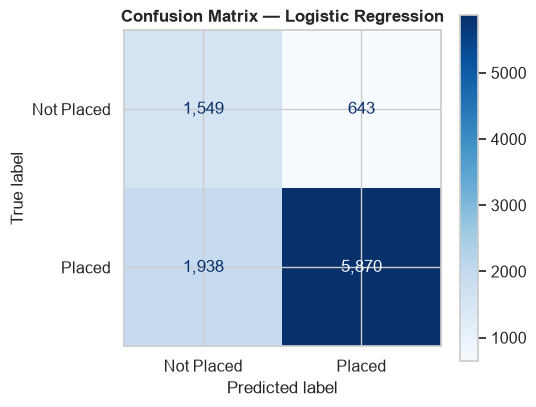

In [23]:
# Confusion matrix at the default 0.5 threshold (balanced class weights already shift it toward catching at-risk students)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=['Not Placed', 'Placed'],
                                      cmap='Blues', values_format=',', ax=ax)
ax.set_title(f'Confusion Matrix — {best_name}', fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Model Interpretation

### 9.1 What drives the prediction? (Permutation importance)
Permutation importance measures how much test ROC-AUC drops when one feature's values are shuffled. It works for any model, so we compare the selected Logistic Regression with Gradient Boosting to check that both agree on the key drivers.

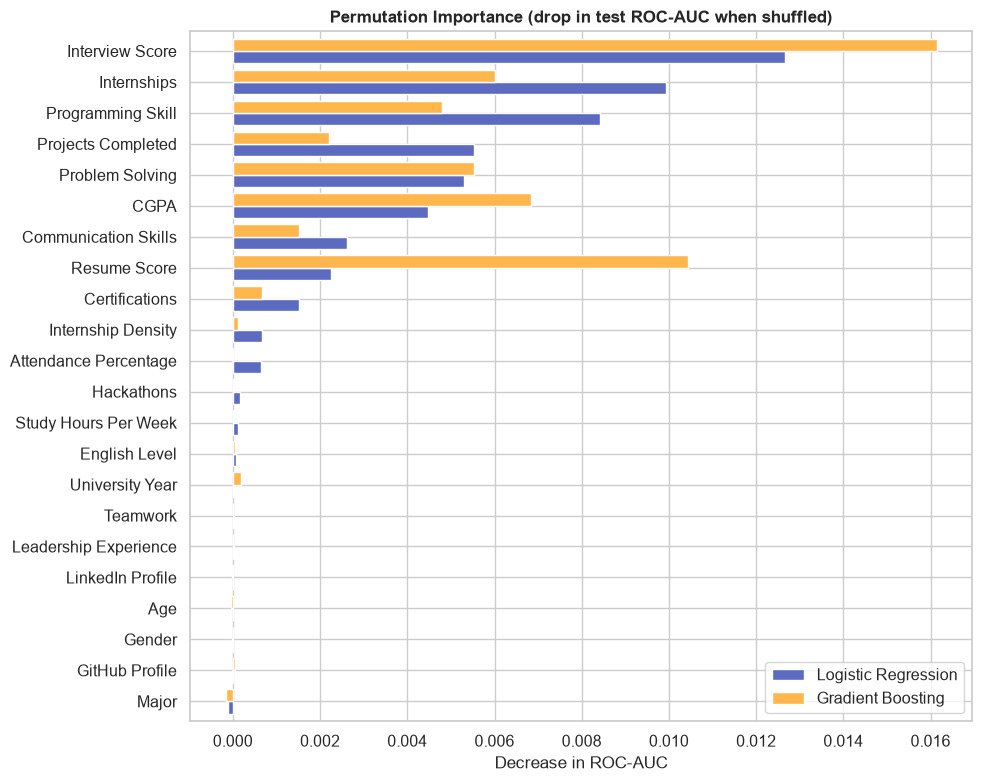

,Logistic Regression,Gradient Boosting
Interview Score,0.0127,0.0161
Internships,0.0099,0.0060
Programming Skill,0.0084,0.0048
Projects Completed,0.0055,0.0022
Problem Solving,0.0053,0.0055
CGPA,0.0045,0.0068
Communication Skills,0.0026,0.0015
Resume Score,0.0022,0.0104


In [24]:
def grouped_permutation_importance(model, n_repeats=5):
    # Shuffle each raw input column (one-hot groups are permuted together)
    res = permutation_importance(model, X_test, y_test, scoring='roc_auc',
                                 n_repeats=n_repeats, random_state=RANDOM_STATE, n_jobs=-1)
    return pd.Series(res.importances_mean, index=X_test.columns)


importance = pd.DataFrame({
    best_name: grouped_permutation_importance(best_model),
    'Gradient Boosting': grouped_permutation_importance(fitted_models['Gradient Boosting']),
}).sort_values(best_name)
importance.index = importance.index.str.replace('_', ' ')

fig, ax = plt.subplots(figsize=(10, 8))
importance.plot.barh(ax=ax, color=['#5C6BC0', '#FFB74D'], width=0.8)
ax.set_title('Permutation Importance (drop in test ROC-AUC when shuffled)', fontweight='bold')
ax.set_xlabel('Decrease in ROC-AUC')
ax.set_ylabel('')
plt.tight_layout()
save_fig(fig, 'feature_importance')
plt.show()

importance.sort_values(best_name, ascending=False).head(8).round(4)

### 9.2 Direction and size of each effect (Logistic Regression odds ratios)
The tuned model uses balanced class weights and strong regularization (C = 0.001). That is good for ranking students, but it shifts predicted probabilities downward and shrinks the coefficients toward zero. The grid search showed that ROC-AUC is flat across C (range < 0.001), so for **interpretation** we refit the same features with no class weighting and light regularization (C = 1). This gives realistic probabilities and unshrunk effect sizes with the same ranking quality.

Coefficients are on standardized features, so each odds ratio describes the effect of a **one-standard-deviation increase** in that feature. An odds ratio of 2.0 means the odds of placement double; 1.0 means no effect.

Interpretation model test ROC-AUC: 0.8031
Mean predicted placement: 77.8% (actual: 78.1%)


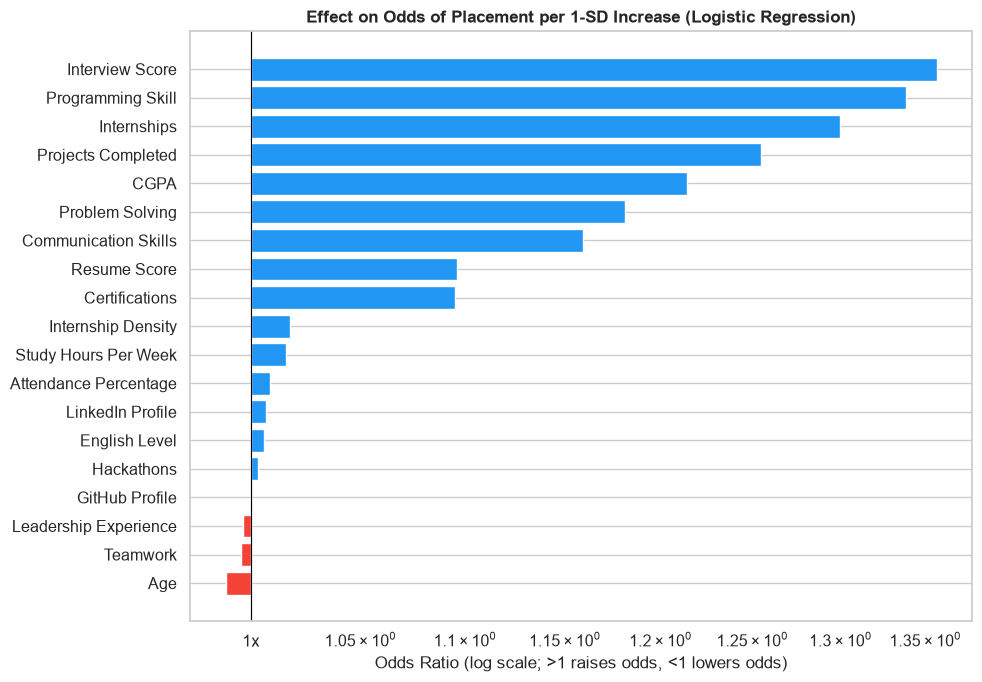

Interview Score       1.36
Programming Skill     1.34
Internships           1.30
Projects Completed    1.25
CGPA                  1.21
Problem Solving       1.18
dtype: float64

In [25]:
interp_model = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)
interp_prob = interp_model.predict_proba(X_test)[:, 1]
print(f'Interpretation model test ROC-AUC: {roc_auc_score(y_test, interp_prob):.4f}')
print(f'Mean predicted placement: {interp_prob.mean():.1%} (actual: {y_test.mean():.1%})')

feature_names = interp_model.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(interp_model.named_steps['model'].coef_[0], index=feature_names)

odds = (coefs[[f'num__{c}' for c in NUMERIC_FEATURES]]
        .rename(lambda s: s.replace('num__', '').replace('_', ' '))
        .pipe(np.exp).sort_values())

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(odds.index, odds.values - 1, left=1,
        color=[PLACED_COLOR if v > 1 else NOT_PLACED_COLOR for v in odds.values])
ax.axvline(1, color='black', linewidth=0.8)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}x'))
ax.set_title('Effect on Odds of Placement per 1-SD Increase (Logistic Regression)', fontweight='bold')
ax.set_xlabel('Odds Ratio (log scale; >1 raises odds, <1 lowers odds)')
plt.tight_layout()
plt.show()

odds.sort_values(ascending=False).head(6).round(2)

### 9.3 What-if: how much does each lever move a typical student?
To turn the model into advice, take every student in the test set and change **one** factor (keeping everything else the same), then average the predicted placement probability. This shows the practical value of, for example, one more internship.

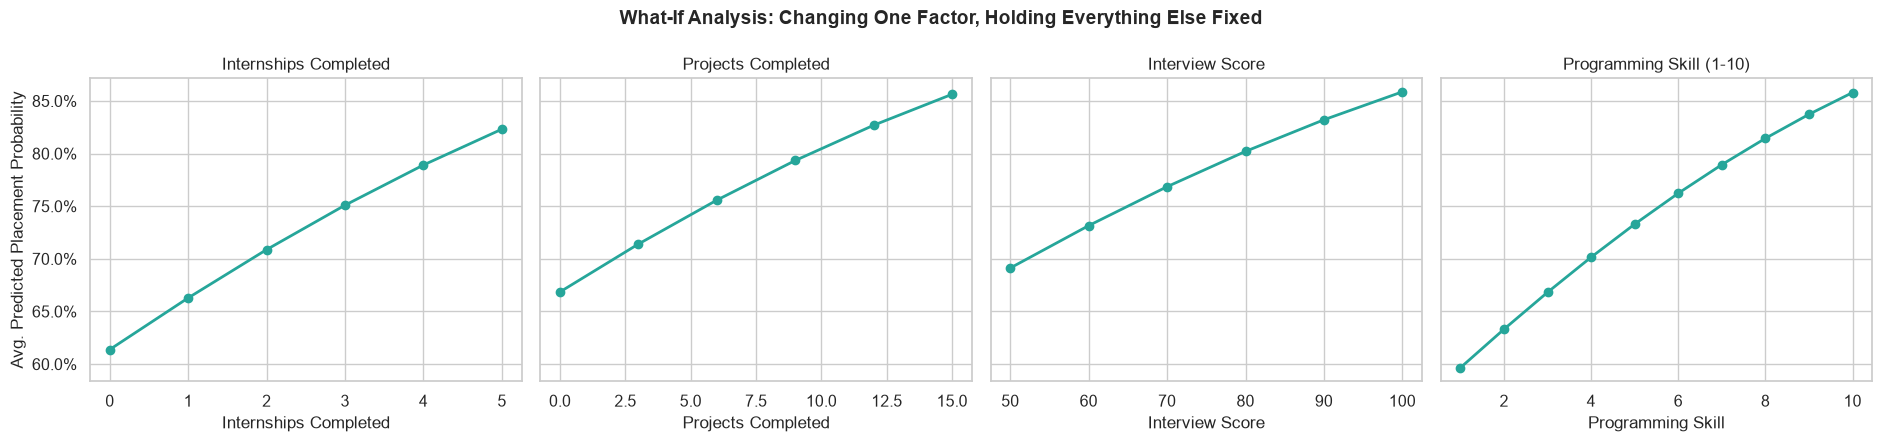

Internships          61% -> 82%
Projects_Completed   67% -> 86%
Interview_Score      69% -> 86%
Programming_Skill    60% -> 86%


In [26]:
def average_placement_if(feature, values):
    # Average predicted placement probability when `feature` is set to each value for all test students
    out = []
    for v in values:
        X_mod = X_test.copy()
        X_mod[feature] = v
        if feature == 'Internships':
            # keep the derived density consistent with the new internship count
            sem = X_mod['University_Year'].map({'Freshman': 2, 'Sophomore': 4, 'Junior': 6, 'Senior': 8})
            X_mod['Internship_Density'] = v / sem
        out.append(interp_model.predict_proba(X_mod)[:, 1].mean())
    return pd.Series(out, index=values)


levers = {
    'Internships': ('Internships Completed', range(0, 6)),
    'Projects_Completed': ('Projects Completed', range(0, 16, 3)),
    'Interview_Score': ('Interview Score', range(50, 101, 10)),
    'Programming_Skill': ('Programming Skill (1-10)', range(1, 11)),
}

fig, axes = plt.subplots(1, 4, figsize=(19, 4.5), sharey=True)
what_if = {}
for ax, (feature, (label, values)) in zip(axes, levers.items()):
    curve = average_placement_if(feature, list(values))
    what_if[feature] = curve
    ax.plot(curve.index, curve.values, marker='o', linewidth=2, color='#26A69A')
    ax.set_title(label)
    ax.set_xlabel(label.split(' (')[0])
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
axes[0].set_ylabel('Avg. Predicted Placement Probability')
fig.suptitle('What-If Analysis: Changing One Factor, Holding Everything Else Fixed', fontsize=14, fontweight='bold')
plt.tight_layout()
save_fig(fig, 'what_if')
plt.show()

for feature, curve in what_if.items():
    print(f'{feature:<20} {curve.iloc[0]:.0%} -> {curve.iloc[-1]:.0%}')

These "what-if" numbers show **associations learned by the model, not proven causal effects.** For example, students who complete more internships may also differ in ways the data doesn't capture, such as motivation or family networks.

### 9.4 Raw gaps vs. gaps after accounting for everything else
Several factors show large gaps in the EDA charts but carry almost no weight in the model. The table below compares, for each factor:
- **Raw gap:** the difference in actual placement rates between the two groups in the data.
- **Model-adjusted gap:** the difference in average predicted placement when *only* that factor is switched for every test student and everything else stays the same.

If the adjusted gap is much smaller than the raw gap, the raw gap is mostly explained by *other* differences between the groups, such as interview scores or programming skill.

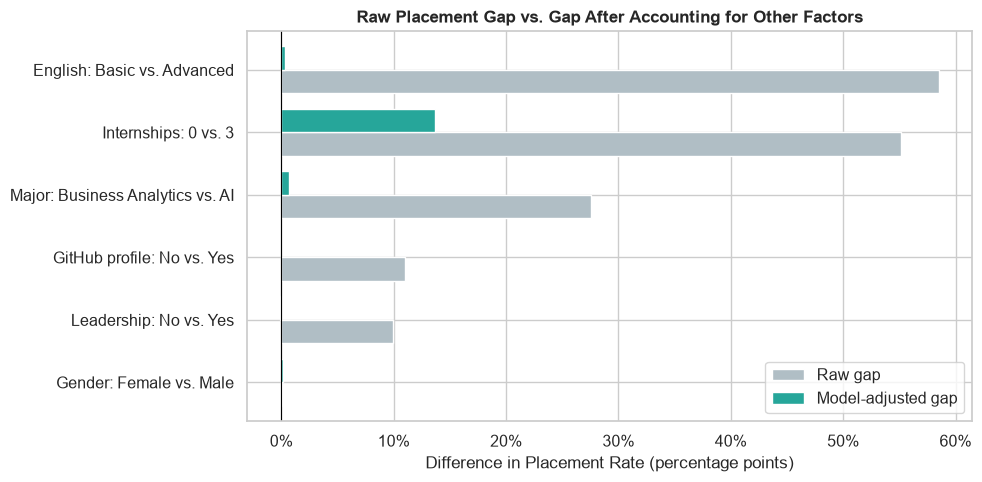

,Raw gap,Model-adjusted gap
Comparison,,
Internships: 0 vs. 3,+55.1%,+13.7%
English: Basic vs. Advanced,+58.6%,+0.3%
Major: Business Analytics vs. AI,+27.6%,+0.7%
GitHub profile: No vs. Yes,+11.0%,-0.0%
Leadership: No vs. Yes,+10.0%,-0.1%
Gender: Female vs. Male,+0.1%,+0.2%


In [27]:
comparisons = [
    # (label, column, low value, high value)
    ('Internships: 0 vs. 3', 'Internships', 0, 3),
    ('English: Basic vs. Advanced', 'English_Level', 0, 2),
    ('Major: Business Analytics vs. AI', 'Major', 'Business Analytics', 'Artificial Intelligence'),
    ('GitHub profile: No vs. Yes', 'GitHub_Profile', 0, 1),
    ('Leadership: No vs. Yes', 'Leadership_Experience', 0, 1),
    ('Gender: Female vs. Male', 'Gender', 'Female', 'Male'),
]

rows = []
for label, col, low, high in comparisons:
    raw_gap = df.loc[df[col] == high, 'Placed'].mean() - df.loc[df[col] == low, 'Placed'].mean()
    adjusted = average_placement_if(col, [low, high])
    rows.append({'Comparison': label, 'Raw gap': raw_gap, 'Model-adjusted gap': adjusted.iloc[1] - adjusted.iloc[0]})

gap_table = pd.DataFrame(rows).set_index('Comparison')

fig, ax = plt.subplots(figsize=(10, 5))
gap_table.sort_values('Raw gap').plot.barh(ax=ax, color=['#B0BEC5', '#26A69A'], width=0.75)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Raw Placement Gap vs. Gap After Accounting for Other Factors', fontweight='bold')
ax.set_xlabel('Difference in Placement Rate (percentage points)')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_ylabel('')
plt.tight_layout()
save_fig(fig, 'raw_vs_adjusted')
plt.show()

gap_table.style.format('{:+.1%}')

In [28]:
# Why does the English gap shrink? Compare skill profiles by English proficiency
(df.groupby('English_Proficiency')[['Interview_Score', 'Programming_Skill', 'Internships', 'CGPA']]
   .mean().reindex(['Basic', 'Intermediate', 'Advanced']).round(2))

,Interview_Score,Programming_Skill,Internships,CGPA
English_Proficiency,,,,
Basic,52.91,5.00,1.82,2.84
Intermediate,67.24,6.27,3.17,2.99
Advanced,80.43,7.39,4.30,3.14


**Interpretation**
- **Internships keep a large independent effect.** Even with everything else held fixed, they remain one of the biggest levers. Part of the raw gap, however, reflects the fact that students with more internships are also stronger in other areas.
- **English proficiency, major, GitHub, and leadership mostly act as proxies.** For example, students with Basic English average an interview score of about 53, compared with about 80 for Advanced. Once interview score and the other skills are known, English level adds almost nothing. The large gaps in the EDA are real, but they work *through* interview performance, programming skill, and experience.
- **Gender has no effect, raw or adjusted.**

## 10. Findings, Recommendations & Next Steps

### Findings
1. **Placement is predictable from pre-graduation factors.** The best models reach a test ROC-AUC of about 0.80, compared with 0.50 for chance. Ranking students by predicted risk lets advisors reach about **half of all at-risk students by contacting only the top 20%** of the list — more than twice as efficient as random outreach.
2. **A simple model is enough.** Logistic Regression scores slightly *higher* than Random Forest and Gradient Boosting. Bootstrap tests show the gap is statistically significant but practically negligible (≤ 0.004 AUC), so the transparent model is used. Its effects are additive: improving any key factor helps, and there is no single "magic combination."
3. **Five factors drive the prediction:** **interview score, programming skill, internships, projects completed, and CGPA**, followed by problem-solving and communication skills. All five differ significantly between placed and not-placed students, with medium-to-large effect sizes (p < 0.001). Experience and job-readiness skills carry more weight than grades.
4. **Several big raw gaps are proxies, not independent drivers.** English proficiency, major, GitHub profile, and leadership all show large raw differences in placement rates. Once interview performance, skills, and experience are accounted for, those differences nearly vanish. For example, students with Basic English place far less often mainly because they score much lower in interviews.
5. **Some popular advice matters little in this data.** A LinkedIn profile, more study hours, attendance, hackathons, and age add essentially nothing once the other factors are known.
6. **No gender effect.** Placement rates do not differ by gender (chi-square p = 0.90), and gender carries no weight in the model.

### Recommendations
- **For career services:** Score students every term and **prioritize outreach to the highest-risk 20–30%** of the list, which reaches about half to two-thirds of at-risk students. Focus that outreach on the levers the model identifies: internship placement help, mock interviews, and technical-skill and project support.
- **For students:** Prioritize **internships**, **interview practice**, and **hands-on projects that build programming skill**. These are the levers with the largest independent effect. Grades matter too, but less.
- **For programs with low placement rates (e.g., Business Analytics, Electrical Engineering):** The model attributes their gap to students' skill and experience profiles, not to the major itself. Building internship pipelines and technical and interview preparation inside those programs targets the actual cause.
- **For students with Basic or Intermediate English:** Focus support on **interview and communication coaching**. The data suggests that interviews are where these students lose ground.

### Limitations
- The data is a public Kaggle dataset of uncertain origin and may be synthetic. Results should be validated on a university's own records before acting on them.
- The findings are correlational, not causal.
- A ROC-AUC of about 0.80 is useful, not perfect: the model misses about 29% of at-risk students at the default cutoff, and more than half of the students it flags turn out to be placed. It should **guide where advisors start, not decide who gets help.**

### Next Steps
- Validate on real institutional data, ideally with a time-based split (train on past cohorts, test on the most recent one).
- Add factors that are currently missing, such as the timing of internships, employer networking, and regional job-market conditions.
- Predict **starting salary** for placed students as a second, regression-based target.
- Calibrate predicted probabilities and choose an operating threshold based on how many students advisors can actually serve.
- Monitor the model for fairness across gender, major, and other groups once it is deployed.